# 06 — Ekstraksi Fitur Warna, Tekstur GLCM, dan Morfologi Mask

## Ringkasan utama

Notebook ini mendokumentasikan **ekstraksi fitur tetap (fixed-length)** untuk seluruh kohort berpasangan **2.226 citra** EBHI-SEG (train 1.535, val 372, test 319) menggunakan **empat komparator segmentasi beku**: `otsu_M0`, `otsu_M2`, `k4_M0` (konfigurasi terpilih), dan `k4_M1`.

Tiga set fitur didefinisikan:

- **Set A — appearance (10 fitur):** rerata dan simpangan baku populasi kanal CIE Lab (`L*`, `a*`, `b*`) serta empat properti GLCM yang dirata-ratakan atas delapan pasangan jarak–sudut.
- **Set B — morfologi mask (19 fitur):** empat deskriptor global mask dan ringkasan rerata/simpangan baku populasi/median untuk lima ukuran per komponen (`area_rel`, `perimeter_rel`, `circularity`, `eccentricity`, `solidity`).
- **Set C — gabungan (29 fitur):** konkatenasi A dan B untuk setiap komparator.

**Batas ilmiah:** fitur citra tidak pernah membaca *reference mask*; fitur morfologi hanya memakai mask prediksi dari artefak `train` yang sudah dibekukan. Tidak ada pelatihan ulang, *tuning*, atau evaluasi `test` di sini.


## Konteks, kontrak fitur, dan artefak kanonik

**Pertanyaan:** bagaimana mengubah citra histopatologi dan mask segmentasinya menjadi vektor fitur numerik yang konsisten, terdokumentasi, dan siap dipakai oleh klasifikasi SVM A/B/C pada tahap berikutnya?

### Aturan yang dipertahankan

- `split_manifest.csv` adalah otoritas kohort; checksum *raw-byte*-nya diverifikasi sebelum dan sesudah eksekusi.
- **Set A** dihitung dari citra RGB asli (`uint8`). Konversi Lab memakai kontrak yang sama dengan segmentasi: RGB `float32 / 255` lalu `COLOR_RGB2LAB`.
- **GLCM:** kuantisasi tetap 16 level dengan interval `gray // 16`, jarak `(1, 2)`, sudut `0°, 45°, 90°, 135°`, `symmetric=True`, `normed=True`; nilai akhir adalah rerata atas delapan pasangan. Korelasi non-finit (mask konstan) diganti `0.0`.
- **Set B** dihitung dari mask prediksi biner. Komponen memakai konektivitas-8. `perimeter_rel = P / sqrt(H × W)` sesuai rumusan laporan, `area_rel = A / (H × W)`, dan `circularity = 4πA/P²` (perimeter nol → `0.0`).
- `mask_edge_foreground_fraction` = piksel *foreground* pada komponen yang menyentuh tepi citra dibagi total piksel *foreground*.
- Mask kosong menghasilkan seluruh fitur numerik `0.0` dan `mask_is_empty = 1`.
- Perbandingan komparator: `otsu_M0` (Otsu mentah), `otsu_M2` (Otsu terproses terbaik), `k4_M0` (K-means mentah terbaik sekaligus konfigurasi terpilih), `k4_M1` (K-means terproses terbaik).

**Sumber angka kanonik:** `scripts/extract_features.py` menulis `results/features/appearance.csv`, `features_<metode>.csv`, `morphology_diagnostics.csv`, dan `feature_manifest.json`. Notebook ini memuat artefak tersebut, memvalidasi skema dan provenance, lalu menghitung ulang sejumlah kecil sampel untuk uji paritas.


In [1]:
%matplotlib inline

import json
from pathlib import Path
import platform

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from ebhi_dip import (
    APPEARANCE_FEATURE_NAMES,
    DEFAULT_FEATURE_METHODS,
    EXPECTED_CATEGORIES,
    FEATURE_NAMES,
    MORPHOLOGY_FEATURE_NAMES,
    PRIMARY_FEATURE_METHOD,
    build_feature_tables,
    configure_notebook_style,
    find_project_root,
    finish_figure,
    load_split_manifest,
    load_validation_results,
    method_label,
    selection_ranking_key,
    sha256_bytes,
    summarize_validation_methods,
    validate_feature_table,
    verify_frozen_split,
)

PROJECT_ROOT_OVERRIDE = None
DATA_ROOT_OVERRIDE = None
EXPORT_FIGURES = False
FEATURE_METHODS = DEFAULT_FEATURE_METHODS
PRIMARY_METHOD = PRIMARY_FEATURE_METHOD
PARITY_SAMPLES_PER_SPLIT = 2

ROOT = find_project_root(override=PROJECT_ROOT_OVERRIDE)
SPLIT_SHA = verify_frozen_split(ROOT)
FEATURE_DIR = ROOT / "results/features"
configure_notebook_style()

protected_files = {
    "split_manifest": ROOT / "data/metadata/split_manifest.csv",
    "otsu_config": ROOT / "configs/otsu_raw.json",
    "otsu_morph_val": ROOT / "results/otsu_morph_val.csv",
    "kmeans_morph_val": ROOT / "results/kmeans_morph_val.csv",
    "kmeans_run": ROOT / "results/kmeans_morph_val_run.json",
    "feature_manifest": FEATURE_DIR / "feature_manifest.json",
    "appearance": FEATURE_DIR / "appearance.csv",
    "diagnostics": FEATURE_DIR / "morphology_diagnostics.csv",
}
protected_files.update(
    {f"features_{method}": FEATURE_DIR / f"features_{method}.csv" for method in FEATURE_METHODS}
)
input_hashes_before = {name: sha256_bytes(path) for name, path in protected_files.items()}

display(
    pd.DataFrame(
        {
            "komponen": [
                "Python",
                "NumPy",
                "pandas",
                "Matplotlib",
                "scikit-image",
                "Konfigurasi terpilih",
                "Jumlah komparator",
            ],
            "nilai": [
                platform.python_version(),
                np.__version__,
                pd.__version__,
                matplotlib.__version__,
                __import__("skimage").__version__,
                PRIMARY_METHOD,
                len(FEATURE_METHODS),
            ],
        }
    )
)


,komponen,nilai
0,Python,3.14.0
1,NumPy,2.4.4
2,pandas,3.0.2
3,Matplotlib,3.10.9
4,scikit-image,0.26.0
5,Konfigurasi terpilih,k4_M0
6,Jumlah komparator,4


## 1. Komparator beku dan rasional seleksi pada validasi

Empat komparator dipilih dari hasil validasi yang sudah tersimpan: satu konfigurasi mentah dan satu terproses terbaik untuk tiap keluarga. `k4_M0` adalah kandidat *image-dependent* terbaik sekaligus konfigurasi utama yang dipakai untuk tabel fitur morfologi kanonik.


In [2]:
validation = load_validation_results(ROOT)
summary = summarize_validation_methods(validation)

comparators = summary.loc[list(FEATURE_METHODS), [
    "mean_category_dice",
    "mean_category_iou",
    "delta_dice_vs_control",
]].copy()
comparators.insert(0, "label", [method_label(method) for method in comparators.index])
comparators.insert(1, "peran", [
    "Otsu mentah",
    "Otsu terproses terbaik",
    "K-means mentah terbaik (terpilih)",
    "K-means terproses terbaik",
])
comparators["label"] = comparators["label"].str.replace(", ", " · ", regex=False)
display(
    comparators.style.format(
        {
            "mean_category_dice": "{:.4f}",
            "mean_category_iou": "{:.4f}",
            "delta_dice_vs_control": "{:+.4f}",
        }
    )
)

best_candidate = max(
    (method for method in summary.index if method != "all_foreground"),
    key=lambda method: selection_ranking_key(summary, method),
)
assert best_candidate == PRIMARY_METHOD
assert round(float(summary.loc["k4_M0", "mean_category_dice"]), 4) == 0.7761
assert round(float(summary.loc["otsu_M2", "mean_category_dice"]), 4) == 0.7288
print(f"Komparator beku siap dipakai: {', '.join(FEATURE_METHODS)}; kandidat terbaik = {best_candidate}.")


,label,peran,mean_category_dice,mean_category_iou,delta_dice_vs_control
method,,,,,
otsu_M0,Otsu M0,Otsu mentah,0.7232,0.5788,-0.0534
otsu_M2,Otsu M2,Otsu terproses terbaik,0.7288,0.5886,-0.0479
k4_M0,K-means k=4 · M0,K-means mentah terbaik (terpilih),0.7761,0.6427,-0.0006
k4_M1,K-means k=4 · M1,K-means terproses terbaik,0.7760,0.6426,-0.0007


Komparator beku siap dipakai: otsu_M0, otsu_M2, k4_M0, k4_M1; kandidat terbaik = k4_M0.


## 2. Memuat dan memvalidasi tabel fitur kanonik

`validate_feature_table` memeriksa kolom wajib, keunikan kunci `sample_id` (atau `sample_id × method`), nilai hingga, kategori yang diharapkan, serta batas `[0, 1]` untuk fraksi dan sifat biner `mask_is_empty`.


In [3]:
appearance = pd.read_csv(protected_files["appearance"])
combined = {method: pd.read_csv(protected_files[f"features_{method}"]) for method in FEATURE_METHODS}
diagnostics = pd.read_csv(protected_files["diagnostics"])
manifest = json.loads(protected_files["feature_manifest"].read_text(encoding="utf-8"))
split_df = load_split_manifest(ROOT, verify=False)

validate_feature_table(appearance, feature_names=APPEARANCE_FEATURE_NAMES, require_method=False)
for method, table in combined.items():
    validate_feature_table(table)

assert manifest["split_sha256"] == SPLIT_SHA
assert tuple(manifest["methods"]) == FEATURE_METHODS
assert set(manifest["feature_sets"]["C"]) == set(FEATURE_NAMES)

cohort = (
    appearance.groupby(["split", "category"], observed=True)
    .size()
    .unstack("split")
    .reindex(list(EXPECTED_CATEGORIES))
    .fillna(0)
    .astype(int)
)
cohort["total"] = cohort.sum(axis=1)
display(cohort)

shape_table = pd.DataFrame(
    [
        {"artefak": "appearance.csv", "baris": len(appearance), "kolom": len(appearance.columns)},
        *[
            {
                "artefak": f"features_{method}.csv",
                "baris": len(table),
                "kolom": len(table.columns),
            }
            for method, table in combined.items()
        ],
        {"artefak": "morphology_diagnostics.csv", "baris": len(diagnostics), "kolom": len(diagnostics.columns)},
    ]
)
display(shape_table)
print(f"Total citra: {len(appearance):,} | Total baris diagnostik: {len(diagnostics):,} | Checksum split cocok.")


split,test,train,val,total
category,,,,
Adenocarcinoma,124,540,131,795
High-grade IN,35,131,20,186
Low-grade IN,86,444,107,637
Normal,12,54,10,76
Polyp,54,324,96,474
Serrated adenoma,8,42,8,58


,artefak,baris,kolom
0,appearance.csv,2226,14
1,features_otsu_M0.csv,2226,34
2,features_otsu_M2.csv,2226,34
3,features_k4_M0.csv,2226,34
4,features_k4_M1.csv,2226,34
5,morphology_diagnostics.csv,8904,12


Total citra: 2,226 | Total baris diagnostik: 8,904 | Checksum split cocok.


## 3. Katalog fitur: set A, set B, dan set C

Setiap nama fitur memiliki definisi tetap agar kolom dapat dipakai ulang tanpa *preprocessing* tambahan. Fitur morfologi per komponen diringkas dengan tiga statistik sehingga jumlah fitur tidak bergantung pada jumlah komponen mask.


In [4]:
appearance_definitions = {
    "lab_l_mean": "Rerata kanal L* (CIE Lab) seluruh piksel",
    "lab_l_std": "Simpangan baku populasi kanal L*",
    "lab_a_mean": "Rerata kanal a* (CIE Lab)",
    "lab_a_std": "Simpangan baku populasi kanal a*",
    "lab_b_mean": "Rerata kanal b* (CIE Lab)",
    "lab_b_std": "Simpangan baku populasi kanal b*",
    "glcm_contrast": "Rerata GLCM contrast atas 8 pasangan jarak-sudut",
    "glcm_homogeneity": "Rerata GLCM homogeneity atas 8 pasangan jarak-sudut",
    "glcm_energy": "Rerata GLCM energy atas 8 pasangan jarak-sudut",
    "glcm_correlation": "Rerata GLCM correlation; non-finit -> 0",
}
global_mask_definitions = {
    "mask_foreground_fraction": "Piksel foreground / total piksel citra",
    "mask_component_count": "Jumlah komponen foreground (konektivitas-8)",
    "mask_edge_foreground_fraction": "Foreground pada komponen penyentuh tepi / total foreground",
    "mask_is_empty": "1 jika mask kosong, selain itu 0",
}
region_measure_labels = {
    "area_rel": "area komponen / luas citra",
    "perimeter_rel": "perimeter komponen / sqrt(luas citra)",
    "circularity": "4*pi*area / perimeter^2 (perimeter nol -> 0)",
    "eccentricity": "eksentrisitas komponen (regionprops)",
    "solidity": "solidity komponen (regionprops)",
}

catalog_rows = [
    {"fitur": name, "set": "A", "definisi": definition}
    for name, definition in appearance_definitions.items()
]
catalog_rows += [
    {"fitur": name, "set": "B", "definisi": definition}
    for name, definition in global_mask_definitions.items()
]
for measure, measure_label in region_measure_labels.items():
    for statistic in ("mean", "std", "median"):
        catalog_rows.append(
            {
                "fitur": f"region_{measure}_{statistic}",
                "set": "B",
                "definisi": f"{statistic} lintas komponen dari {measure_label}",
            }
        )
catalog = pd.DataFrame(catalog_rows)
assert tuple(catalog["fitur"]) == FEATURE_NAMES

display(
    pd.DataFrame(
        [
            {"set": "A", "jumlah": len(APPEARANCE_FEATURE_NAMES), "cakupan": "warna Lab + tekstur GLCM"},
            {"set": "B", "jumlah": len(MORPHOLOGY_FEATURE_NAMES), "cakupan": "morfologi mask prediksi"},
            {"set": "C", "jumlah": len(FEATURE_NAMES), "cakupan": "A + B"},
        ]
    )
)
display(catalog)


,set,jumlah,cakupan
0,A,10,warna Lab + tekstur GLCM
1,B,19,morfologi mask prediksi
2,C,29,A + B


,fitur,set,definisi
0,lab_l_mean,A,Rerata kanal L* (CIE Lab) seluruh piksel
1,lab_l_std,A,Simpangan baku populasi kanal L*
2,lab_a_mean,A,Rerata kanal a* (CIE Lab)
3,lab_a_std,A,Simpangan baku populasi kanal a*
4,lab_b_mean,A,Rerata kanal b* (CIE Lab)
5,lab_b_std,A,Simpangan baku populasi kanal b*
6,glcm_contrast,A,Rerata GLCM contrast atas 8 pasangan jarak-sudut
7,glcm_homogeneity,A,Rerata GLCM homogeneity atas 8 pasangan jarak-...
8,glcm_energy,A,Rerata GLCM energy atas 8 pasangan jarak-sudut
9,glcm_correlation,A,Rerata GLCM correlation; non-finit -> 0


## 4. Statistik deskriptif per kategori pada konfigurasi terpilih

Tabel berikut merangkum rerata fitur untuk `k4_M0` pada tiap kategori diagnostik. Perbedaan rerata antar kategori bersifat deskriptif dan belum menunjukkan daya pisah klasifikasi.


In [5]:
primary = combined[PRIMARY_METHOD]
display_columns = [
    "lab_l_mean",
    "lab_a_mean",
    "lab_b_mean",
    "glcm_contrast",
    "glcm_homogeneity",
    "mask_foreground_fraction",
    "mask_component_count",
    "region_circularity_median",
    "region_eccentricity_median",
    "region_solidity_median",
]
category_means = (
    primary.groupby("category", observed=True)[list(FEATURE_NAMES)]
    .mean()
    .reindex(list(EXPECTED_CATEGORIES))
)
display(category_means[display_columns].style.format("{:.4f}"))

overall = primary[list(FEATURE_NAMES)].agg(["min", "median", "mean", "max"]).T
display(overall.style.format("{:.4f}"))


,lab_l_mean,lab_a_mean,lab_b_mean,glcm_contrast,glcm_homogeneity,mask_foreground_fraction,mask_component_count,region_circularity_median,region_eccentricity_median,region_solidity_median
category,,,,,,,,,,
Adenocarcinoma,47.3091,37.2929,-40.5025,6.6041,0.4788,0.8577,19.5597,0.4080,0.6211,0.9787
High-grade IN,46.6296,37.6242,-41.1587,5.5179,0.5184,0.8426,17.9731,0.3471,0.6318,0.9759
Low-grade IN,45.6350,37.3306,-37.9272,6.3031,0.4823,0.8668,23.7535,0.2483,0.5268,0.9914
Normal,51.0573,31.6823,-35.0215,6.3464,0.4784,0.7974,57.1842,0.1810,0.4998,0.9927
Polyp,43.8716,30.5356,-33.0919,5.9202,0.4984,0.8447,38.0907,0.1542,0.4174,0.9932
Serrated adenoma,44.5277,29.4155,-30.3115,4.7229,0.5269,0.8275,23.7586,0.1764,0.5683,0.9917


,min,median,mean,max
lab_l_mean,32.8864,46.0255,46.0968,62.0797
lab_l_std,11.2592,21.5886,21.6113,35.3356
lab_a_mean,0.5752,35.5474,35.4957,71.2248
lab_a_std,4.7925,13.3473,13.9920,32.0864
lab_b_mean,-71.3842,-37.8348,-37.7897,6.9132
lab_b_std,6.3992,15.2599,15.5350,30.6128
glcm_contrast,1.5185,6.0362,6.2238,14.2986
glcm_homogeneity,0.3374,0.4824,0.4885,0.7280
glcm_energy,0.0837,0.1265,0.1343,0.4290
glcm_correlation,0.4632,0.7485,0.7467,0.9366


## 5. Distribusi fitur terpilih per kategori diagnostik

Enam panel memperlihatkan sebaran fitur yang mewakili warna, tekstur, cakupan area, bentuk, eksentrisitas, dan soliditas. Kotak menunjukkan kuartil, garis tengah menunjukkan median, dan titik menunjukkan pencilan.


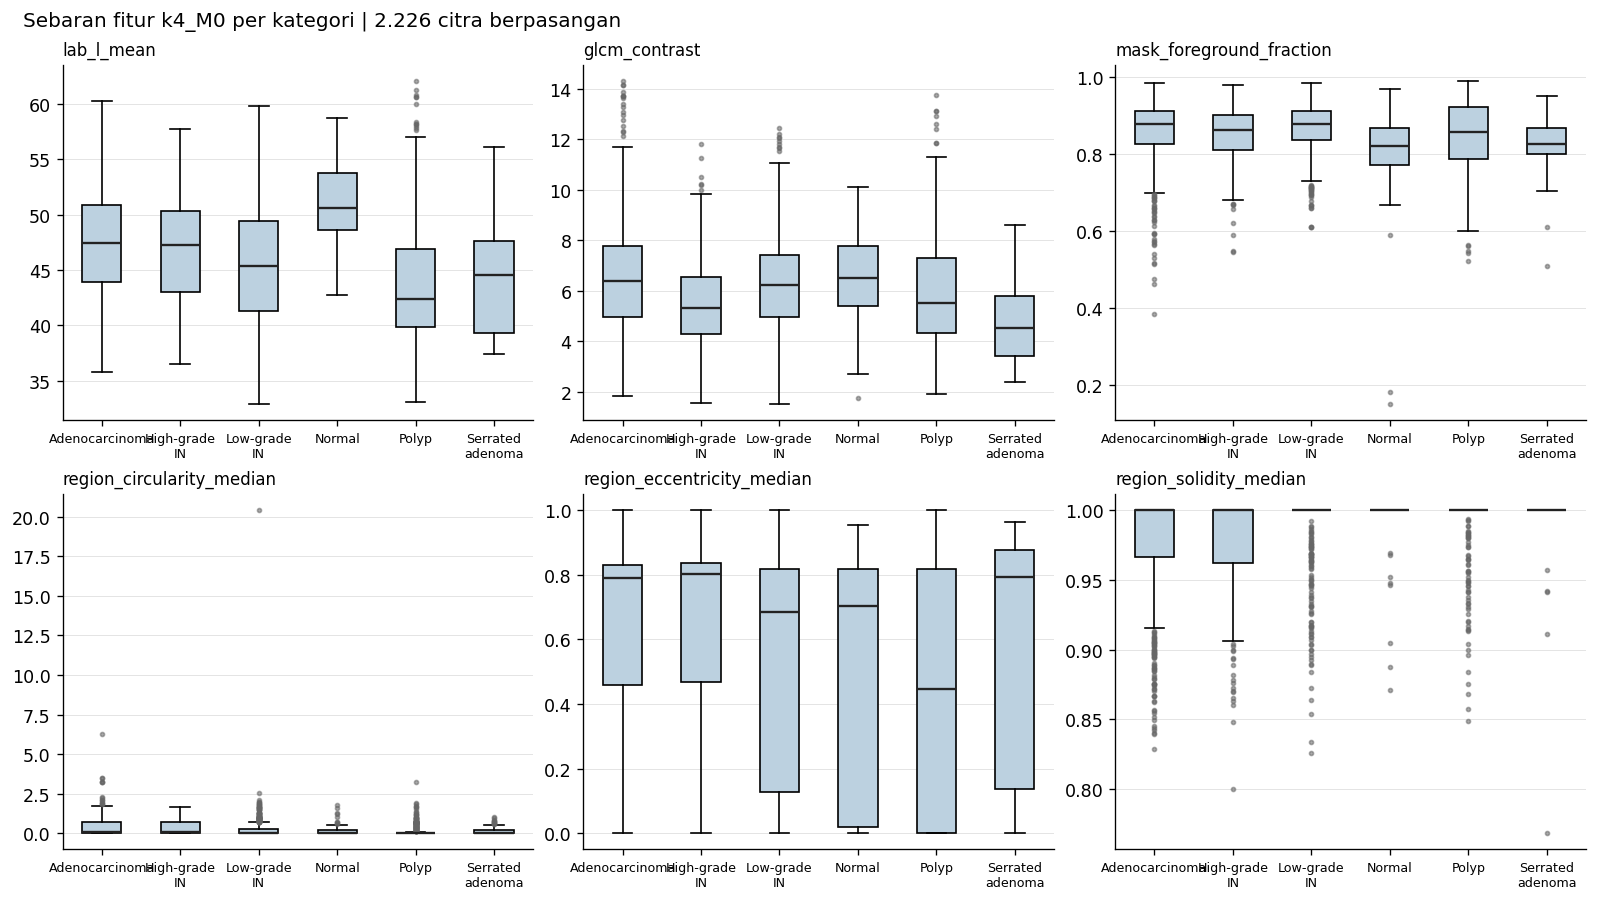

In [6]:
plot_features = [
    "lab_l_mean",
    "glcm_contrast",
    "mask_foreground_fraction",
    "region_circularity_median",
    "region_eccentricity_median",
    "region_solidity_median",
]

fig, axes = plt.subplots(2, 3, figsize=(13.2, 7.4), layout="constrained")
for axis, feature_name in zip(axes.ravel(), plot_features):
    values = [
        primary.loc[primary["category"].eq(category), feature_name].to_numpy()
        for category in EXPECTED_CATEGORIES
    ]
    boxplot = axis.boxplot(
        values,
        tick_labels=[category.replace(" ", "\n") for category in EXPECTED_CATEGORIES],
        patch_artist=True,
        medianprops={"color": "#222222", "linewidth": 1.4},
        flierprops={
            "marker": "o",
            "markersize": 2.4,
            "markerfacecolor": "#666666",
            "markeredgecolor": "#666666",
            "alpha": 0.55,
        },
    )
    for patch in boxplot["boxes"]:
        patch.set_facecolor("#BCD1E0")
    axis.set_title(feature_name, loc="left", fontsize=10)
    axis.grid(axis="y", color="#E4E4E4", linewidth=0.6)
    axis.tick_params(axis="x", labelsize=7.6)

fig.suptitle(
    f"Sebaran fitur {PRIMARY_METHOD} per kategori | 2.226 citra berpasangan",
    fontsize=12,
    x=0.01,
    ha="left",
)
finish_figure(
    fig,
    export_path=(ROOT / "reports/figures/feature_distributions_by_category.png") if EXPORT_FIGURES else None,
)


## 6. Korelasi antar fitur pada set C

Matriks korelasi Pearson membantu mengenali fitur yang sangat redundan sebelum pemodelan hilir. Nilai korelasi tinggi tidak otomatis berarti fitur harus dibuang; keputusan seleksi tetap menjadi bagian dari tahap klasifikasi.


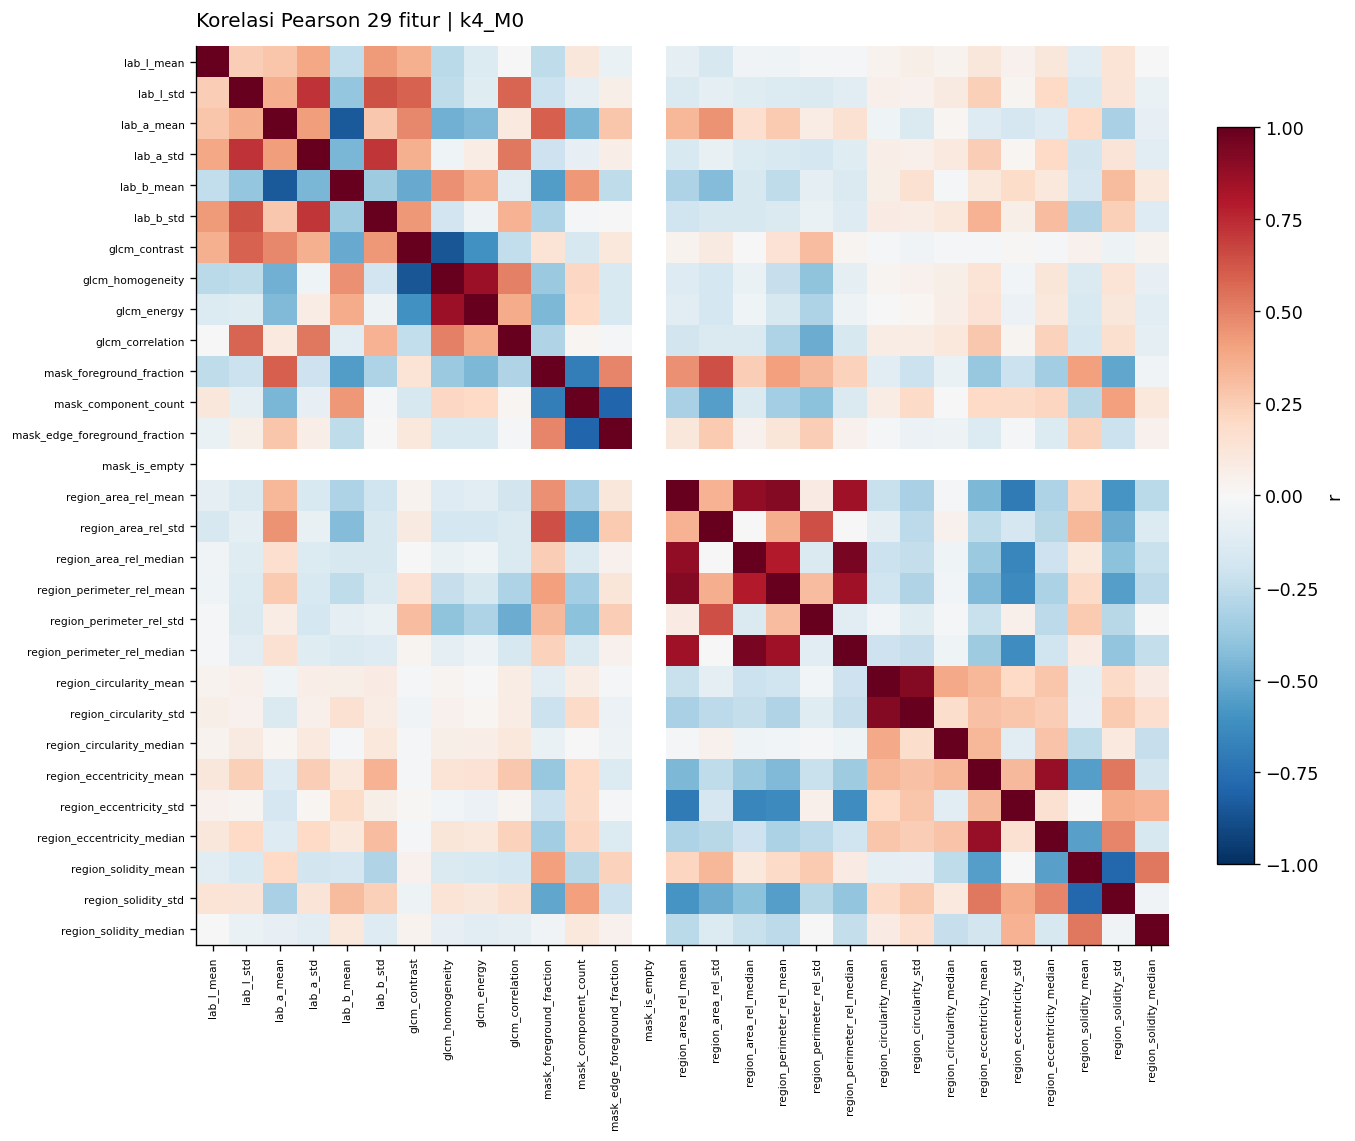

In [7]:
correlation = primary[list(FEATURE_NAMES)].corr(method="pearson")

fig_corr, ax_corr = plt.subplots(figsize=(11.2, 9.4), layout="constrained")
image = ax_corr.imshow(correlation.to_numpy(), cmap="RdBu_r", vmin=-1.0, vmax=1.0, aspect="auto")
positions = np.arange(len(FEATURE_NAMES))
ax_corr.set_xticks(positions, FEATURE_NAMES, rotation=90, fontsize=6.4)
ax_corr.set_yticks(positions, FEATURE_NAMES, fontsize=6.4)
ax_corr.set_title(f"Korelasi Pearson 29 fitur | {PRIMARY_METHOD}", loc="left", pad=12)
fig_corr.colorbar(image, ax=ax_corr, shrink=0.82, label="r")
finish_figure(
    fig_corr,
    export_path=(ROOT / "reports/figures/feature_correlation_heatmap.png") if EXPORT_FIGURES else None,
)


## 7. Sensitivitas fitur morfologi terhadap komparator segmentasi

Perubahan tahap morfologi (`M0` → `M1`/`M2`) mengubah jumlah komponen, cakupan *foreground*, dan bentuk komponen. Tabel dan diagram berikut membandingkan rerata fitur serta diagnostik mask lintas empat komparator beku.


,mask_foreground_fraction,mask_component_count,mask_edge_foreground_fraction,region_circularity_median,region_solidity_mean,empty_masks,zero_perimeter_components,border_components
otsu_M0,0.5455,200.1298,0.7969,0.6578,0.8939,0.0000,143526.0000,70169.0000
otsu_M2,0.5294,69.5508,0.8540,1.0809,0.8679,0.0000,0.0000,41817.0000
k4_M0,0.8534,25.9672,0.9913,0.2894,0.9397,0.0000,28433.0000,12853.0000
k4_M1,0.8521,5.2332,0.9926,0.3778,0.8328,0.0000,0.0000,5563.0000


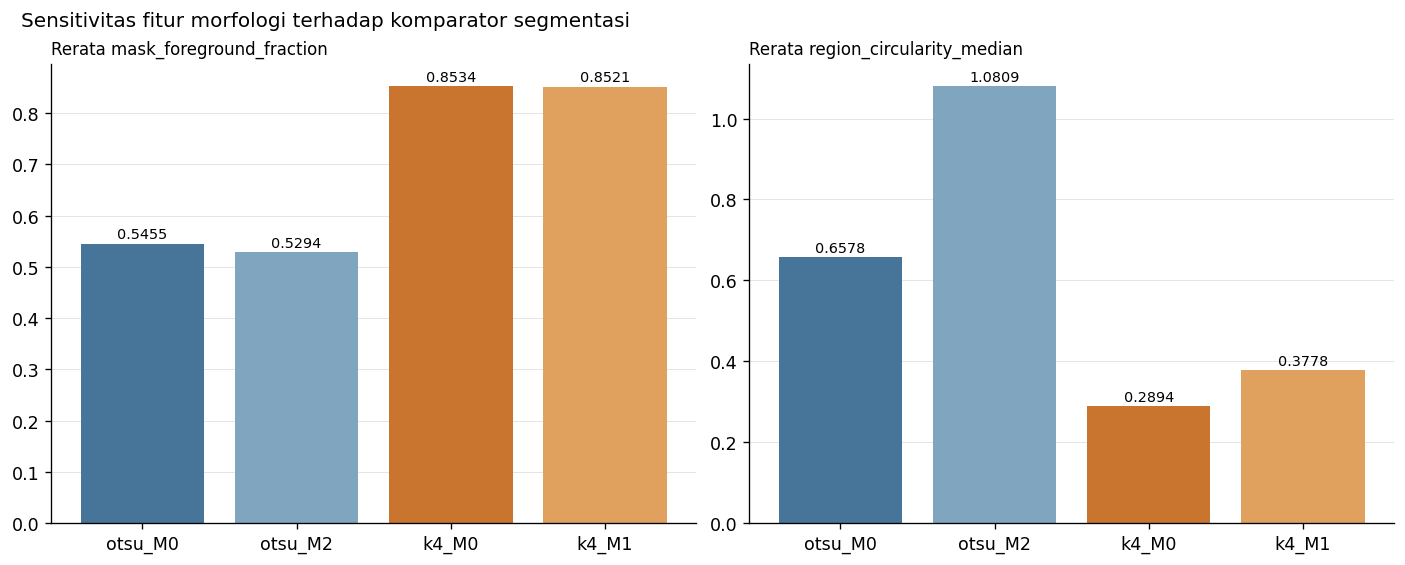

In [8]:
comparator_features = pd.DataFrame(
    {
        method: combined[method][
            [
                "mask_foreground_fraction",
                "mask_component_count",
                "mask_edge_foreground_fraction",
                "region_circularity_median",
                "region_solidity_mean",
            ]
        ].mean()
        for method in FEATURE_METHODS
    }
).T
diagnostic_summary = diagnostics.groupby("method", observed=True).agg(
    empty_masks=("is_empty", "sum"),
    zero_perimeter_components=("zero_perimeter_count", "sum"),
    border_components=("border_component_count", "sum"),
)
comparator_table = pd.concat([comparator_features, diagnostic_summary], axis=1).loc[list(FEATURE_METHODS)]
display(comparator_table.style.format("{:.4f}"))

fig_methods, axes_methods = plt.subplots(1, 2, figsize=(11.6, 4.6), layout="constrained")
for axis, feature_name in zip(
    axes_methods,
    ["mask_foreground_fraction", "region_circularity_median"],
):
    values = comparator_table[feature_name].to_numpy()
    bars = axis.bar(FEATURE_METHODS, values, color=["#47759A", "#7FA6BE", "#C97530", "#E0A15E"])
    for bar, value in zip(bars, values):
        axis.text(
            bar.get_x() + bar.get_width() / 2.0,
            value + 0.005 * max(float(values.max()), 1e-9),
            f"{value:.4f}",
            ha="center",
            va="bottom",
            fontsize=8.6,
        )
    axis.set_title(f"Rerata {feature_name}", loc="left", fontsize=10)
    axis.grid(axis="y", color="#E4E4E4", linewidth=0.6)

fig_methods.suptitle("Sensitivitas fitur morfologi terhadap komparator segmentasi", fontsize=12, x=0.01, ha="left")
finish_figure(
    fig_methods,
    export_path=(ROOT / "reports/figures/feature_method_sensitivity.png") if EXPORT_FIGURES else None,
)


## 8. Uji paritas: hitung ulang sampel dari citra dan artefak beku

Sebanyak dua sampel per split dihitung ulang melalui `build_feature_tables` dan dibandingkan dengan CSV kanonik. Uji ini memastikan artefak yang tersimpan benar-benar dapat direproduksi dari citra RGB, konfigurasi Otsu, model K-means, dan aturan morfologi yang sama.


In [9]:
parity_ids = []
for split_name in ("train", "val", "test"):
    parity_ids.extend(
        split_df.loc[split_df["split"].eq(split_name), "sample_id"]
        .head(PARITY_SAMPLES_PER_SPLIT)
        .tolist()
    )

parity_tables = build_feature_tables(
    ROOT,
    methods=FEATURE_METHODS,
    splits=("train", "val", "test"),
    data_root_override=DATA_ROOT_OVERRIDE,
    sample_ids=parity_ids,
)
validate_feature_table(parity_tables.appearance, feature_names=APPEARANCE_FEATURE_NAMES, require_method=False)

parity_rows = []
for method in FEATURE_METHODS:
    stored = combined[method].set_index("sample_id").loc[parity_ids, list(FEATURE_NAMES)]
    recomputed = parity_tables.combined[method].set_index("sample_id").loc[parity_ids, list(FEATURE_NAMES)]
    max_abs_diff = float(np.abs(stored.to_numpy() - recomputed.to_numpy()).max())
    parity_rows.append(
        {"method": method, "n_samples": len(parity_ids), "max_abs_difference": max_abs_diff}
    )

parity_report = pd.DataFrame(parity_rows)
display(parity_report.style.format({"max_abs_difference": "{:.3e}"}))
assert parity_report["max_abs_difference"].max() < 1e-12
print("Paritas terverifikasi: seluruh fitur sampel uji identik hingga presisi mesin.")


,method,n_samples,max_abs_difference
0,otsu_M0,6,7.105e-15
1,otsu_M2,6,7.105e-15
2,k4_M0,6,7.105e-15
3,k4_M1,6,7.105e-15


Paritas terverifikasi: seluruh fitur sampel uji identik hingga presisi mesin.


## 9. Inventaris artefak dan provenance

Tabel berikut mencatat berkas masukan yang dilindungi beserta ukuran dan awalan SHA-256. Checksum penuh diverifikasi ulang pada sel terakhir untuk memastikan notebook tidak mengubah artefak eksperimen.


In [10]:
artifact_inventory = pd.DataFrame(
    [
        {
            "artefak": path.relative_to(ROOT).as_posix(),
            "bytes": path.stat().st_size,
            "sha256_prefix": input_hashes_before[name][:20],
        }
        for name, path in protected_files.items()
    ]
)
display(artifact_inventory)

display(
    pd.DataFrame(
        [
            {"komponen": "split_sha256", "nilai": manifest["split_sha256"]},
            {"komponen": "primary_method", "nilai": manifest["primary_method"]},
            {"komponen": "jumlah metode", "nilai": len(manifest["methods"])},
            {"komponen": "jumlah sampel train", "nilai": manifest["sample_counts"].get("train", 0)},
            {"komponen": "jumlah sampel val", "nilai": manifest["sample_counts"].get("val", 0)},
            {"komponen": "jumlah sampel test", "nilai": manifest["sample_counts"].get("test", 0)},
        ]
    )
)


,artefak,bytes,sha256_prefix
0,data/metadata/split_manifest.csv,575716,ceeba8e282f77cdb78a9
1,configs/otsu_raw.json,466,dcd8b0867f50f10912fc
2,results/otsu_morph_val.csv,81575,17f24293a33b1fefe78a
3,results/kmeans_morph_val.csv,530758,8a30172c8d2d90b453e7
4,results/kmeans_morph_val_run.json,1066,5ecd034b88d84ecab74b
5,results/features/feature_manifest.json,3695,9b19f8013c3514f64146
6,results/features/appearance.csv,557455,4d7b2c8b8a3c86ff710d
7,results/features/morphology_diagnostics.csv,902500,4ddcaa970774d9b3ebf5
8,results/features/features_otsu_M0.csv,1304348,f2d05d2daeaefdac6627
9,results/features/features_otsu_M2.csv,1324835,23b8aef356f3b53bd56e


,komponen,nilai
0,split_sha256,ceeba8e282f77cdb78a9675618b3dcb6729fbc2339e2d1...
1,primary_method,k4_M0
2,jumlah metode,4
3,jumlah sampel train,1535
4,jumlah sampel val,372
5,jumlah sampel test,319


## Kesimpulan dan serah-terima

- **Fitur kanonik tersedia** untuk 2.226 citra × 4 komparator: set A (10), set B (19), dan set C (29).
- **Konfigurasi utama** untuk klasifikasi hilir adalah `k4_M0`; tiga komparator lain disimpan untuk analisis sensitivitas.
- **Paritas** antara CSV kanonik dan perhitungan ulang dari citra terbukti hingga `1e-12`.
- **Langkah berikutnya (handoff):** notebook klasifikasi SVM A/B/C memakai kolom `sample_id`, `category`, `group_id`, `split`, dan 29 fitur; pemilihan model, *scaling*, dan evaluasi akhir **tidak** dilakukan di notebook ini.


In [11]:
input_hashes_after = {name: sha256_bytes(path) for name, path in protected_files.items()}
assert input_hashes_after == input_hashes_before, "Artefak input berubah saat notebook dieksekusi."
assert set(appearance["sample_id"]) == set(split_df.loc[split_df["pair_status"].eq("paired"), "sample_id"])
print(
    "Selesai: 2.226 citra berpasangan, 4 komparator, set fitur 10/19/29; "
    "seluruh artefak input dan tabel fitur tetap identik."
)


Selesai: 2.226 citra berpasangan, 4 komparator, set fitur 10/19/29; seluruh artefak input dan tabel fitur tetap identik.
